In [1]:
import pandas as pd
import numpy as np
import time
import tracemalloc
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import accuracy_score, mean_squared_error

# 1. Carregar e Dividir Dados

In [2]:
# Classificação
df_class = pd.read_csv('../data/processed/dataset_classification.csv')
X_class = df_class.drop(columns=['TARGET'])
y_class = df_class['TARGET']
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class, y_class, test_size=0.2, random_state=42, stratify=y_class
)

# Regressão
df_reg = pd.read_csv('../data/processed/dataset_regression.csv')
X_reg = df_reg.drop(columns=['TARGET'])
y_reg = df_reg['TARGET']
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)
print("Dados carregados e divididos com sucesso!")

Dados carregados e divididos com sucesso!


# 2. Árvore de Decisão: CLASSIFICAÇÃO

In [3]:
print("--- 1. Árvore Sem Restrições (Overfitting) ---")
tree_overfit_c = DecisionTreeClassifier(random_state=42)
tree_overfit_c.fit(X_train_c, y_train_c)
acc_train_over_c = accuracy_score(y_train_c, tree_overfit_c.predict(X_train_c))
acc_test_over_c = accuracy_score(y_test_c, tree_overfit_c.predict(X_test_c))
print(f"Acurácia Treino: {acc_train_over_c:.4f} | Acurácia Teste: {acc_test_over_c:.4f}")
print(f"Profundidade: {tree_overfit_c.get_depth()} | Nós: {tree_overfit_c.tree_.node_count} | Folhas: {tree_overfit_c.get_n_leaves()}")

print("\n--- 2. Árvore Ajustada (GridSearchCV) ---")
# Testando Gini e Entropia, e limitando o tamanho da árvore
param_grid_c = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 7, 10],
    'min_samples_leaf': [2, 5, 10]
}

grid_c = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid_c, cv=5, scoring='accuracy')

# Medindo o tempo de treinamento computacional
inicio_treino = time.perf_counter()
grid_c.fit(X_train_c, y_train_c)
tempo_treino_c = time.perf_counter() - inicio_treino

best_tree_c = grid_c.best_estimator_
acc_train_best_c = accuracy_score(y_train_c, best_tree_c.predict(X_train_c))
acc_test_best_c = accuracy_score(y_test_c, best_tree_c.predict(X_test_c))

print(f"Melhores hiperparâmetros: {grid_c.best_params_}")
print(f"Tempo de Treinamento: {tempo_treino_c:.4f} segundos")
print(f"Acurácia Treino: {acc_train_best_c:.4f} | Acurácia Teste: {acc_test_best_c:.4f}")
print(f"Profundidade: {best_tree_c.get_depth()} | Nós: {best_tree_c.tree_.node_count} | Folhas: {best_tree_c.get_n_leaves()}")

--- 1. Árvore Sem Restrições (Overfitting) ---
Acurácia Treino: 1.0000 | Acurácia Teste: 0.9851
Profundidade: 141 | Nós: 7571 | Folhas: 3786

--- 2. Árvore Ajustada (GridSearchCV) ---
Melhores hiperparâmetros: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 5}
Tempo de Treinamento: 74.2662 segundos
Acurácia Treino: 0.8202 | Acurácia Teste: 0.8190
Profundidade: 10 | Nós: 217 | Folhas: 109


# 3. VISUALIZAÇÃO DA ÁRVORE (3 Primeiros Níveis)

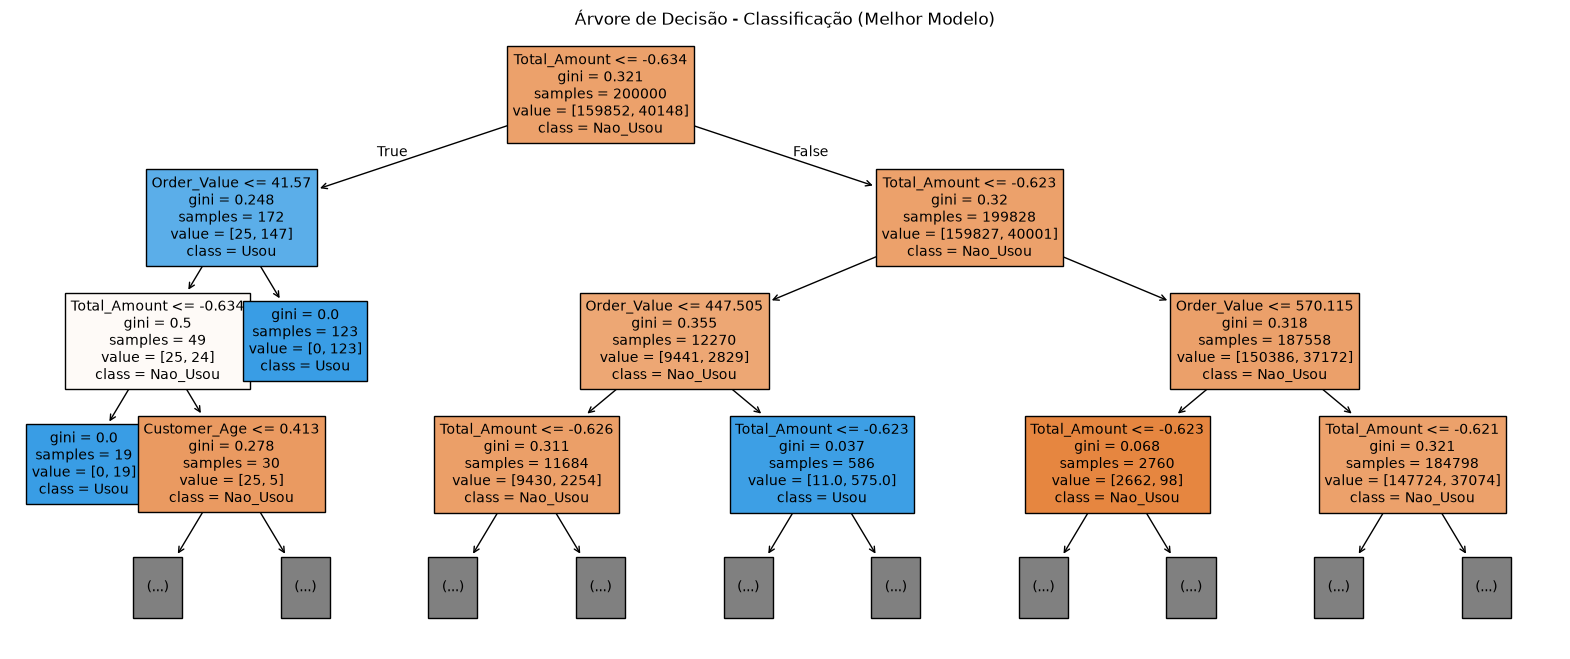

In [4]:
plt.figure(figsize=(20, 8))
plot_tree(best_tree_c, max_depth=3, feature_names=X_class.columns, class_names=['Nao_Usou', 'Usou'], filled=True, fontsize=10)
plt.title("Árvore de Decisão - Classificação (Melhor Modelo)")
plt.savefig('../reports/figures/tree_classification.png', bbox_inches='tight')
plt.show()

# 4. Árvore de Decisão: REGRESSÃO

In [5]:
print("--- 1. Árvore Sem Restrições (Overfitting) ---")
tree_overfit_r = DecisionTreeRegressor(random_state=42)
tree_overfit_r.fit(X_train_r, y_train_r)
rmse_train_over_r = np.sqrt(mean_squared_error(y_train_r, tree_overfit_r.predict(X_train_r)))
rmse_test_over_r = np.sqrt(mean_squared_error(y_test_r, tree_overfit_r.predict(X_test_r)))
print(f"RMSE Treino: {rmse_train_over_r:.4f} | RMSE Teste: {rmse_test_over_r:.4f}")
print(f"Profundidade: {tree_overfit_r.get_depth()} | Nós: {tree_overfit_r.tree_.node_count} | Folhas: {tree_overfit_r.get_n_leaves()}")

print("\n--- 2. Árvore Ajustada (GridSearchCV) ---")
param_grid_r = {
    'criterion': ['squared_error', 'absolute_error'],
    'max_depth': [3, 5, 7, 10],
    'min_samples_leaf': [2, 5, 10]
}

grid_r = GridSearchCV(DecisionTreeRegressor(random_state=42), param_grid_r, cv=5, scoring='neg_mean_squared_error')

# Medindo o tempo de treinamento
inicio_treino_r = time.perf_counter()
grid_r.fit(X_train_r, y_train_r)
tempo_treino_r = time.perf_counter() - inicio_treino_r

best_tree_r = grid_r.best_estimator_
rmse_train_best_r = np.sqrt(mean_squared_error(y_train_r, best_tree_r.predict(X_train_r)))
rmse_test_best_r = np.sqrt(mean_squared_error(y_test_r, best_tree_r.predict(X_test_r)))

print(f"Melhores hiperparâmetros: {grid_r.best_params_}")
print(f"Tempo de Treinamento: {tempo_treino_r:.4f} segundos")
print(f"RMSE Treino: {rmse_train_best_r:.4f} | RMSE Teste: {rmse_test_best_r:.4f}")
print(f"Profundidade: {best_tree_r.get_depth()} | Nós: {best_tree_r.tree_.node_count} | Folhas: {best_tree_r.get_n_leaves()}")

--- 1. Árvore Sem Restrições (Overfitting) ---
RMSE Treino: 0.0355 | RMSE Teste: 0.0365
Profundidade: 22 | Nós: 11899 | Folhas: 5950

--- 2. Árvore Ajustada (GridSearchCV) ---
Melhores hiperparâmetros: {'criterion': 'squared_error', 'max_depth': 10, 'min_samples_leaf': 2}
Tempo de Treinamento: 81.6691 segundos
RMSE Treino: 0.0405 | RMSE Teste: 0.0413
Profundidade: 10 | Nós: 1675 | Folhas: 838


# 5. Visualização da Árvore de Regressão

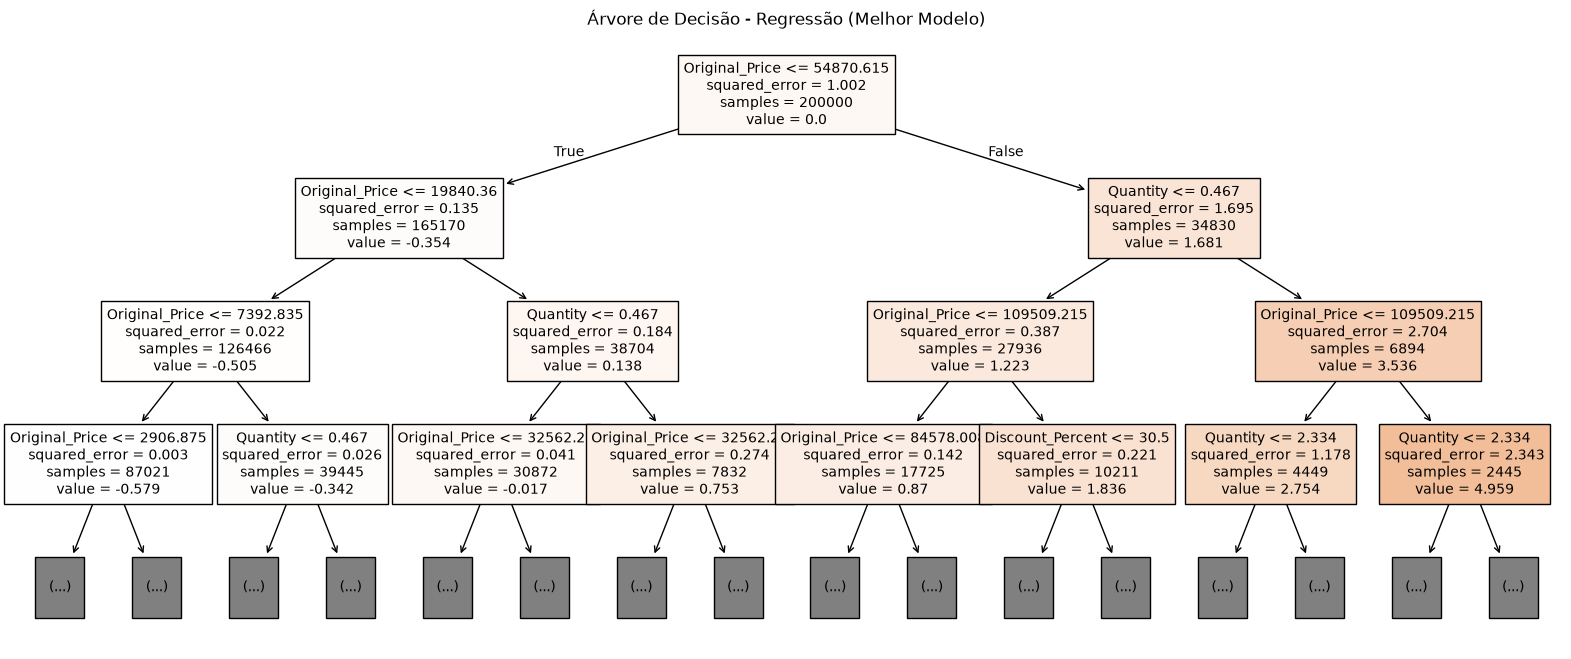

In [6]:
plt.figure(figsize=(20, 8))
plot_tree(best_tree_r, max_depth=3, feature_names=X_reg.columns, filled=True, fontsize=10)
plt.title("Árvore de Decisão - Regressão (Melhor Modelo)")
plt.savefig('../reports/figures/tree_regression.png', bbox_inches='tight')
plt.show()

In [7]:
import joblib
# Salvando os melhores modelos da Árvore de Decisão
joblib.dump(best_tree_c, '../data/processed/best_tree_c.pkl')
joblib.dump(best_tree_r, '../data/processed/best_tree_r.pkl')
print("Modelos de Árvore salvos com sucesso!")

Modelos de Árvore salvos com sucesso!
